제한 및 규칙

- 파인튜닝(Fine-tuning) 금지: 베이스 모델은 동결(requires_grad = False) 상태 유지
- 베이스 모델 자유 선택: torchvision.models 계열(ResNet, EfficientNet, MobileNetV2, VGG 등) 중 택 1 이상
- 데이터 로드/증강은 힌트만 제공(학생이 직접 구현)
- 캐글(Kaggle) 등에서 2개 ~ 6개 내외의 클래스를 가진 이미지 분류 데이터셋을 자유롭게 선정하시오.

 제출물(필수)

1. 실행 파일(.py 또는 .ipynb)
2. 학습 로그(에폭별 train/val loss, accuracy)
3. best 모델 파일(Checkpoint로 저장된 모델)
4. 평가 리포트(MD/PDF):

- 베이스 모델 선택 이유
- 최종 성능 지표(Accuracy + 추가 지표 1개)
- 혼동행렬 + 오분류 분석(5개 이상)
- 개선 아이디어 2개(파인튜닝 제외)

In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()

# 오류 발생시
# sklearn.set_config(display="text")

True

[문제 1] 데이터 로드 & 증강 파이프라인 구성 (힌트 제공) (15점)

요구사항

- 입력 크기: 224 x 224
- 배치 크기: 32
- 훈련/검증 분리: 80 / 20
- 훈련(train)에만 증강 적용
- 클래스 수: 본인이 선택한 데이터셋 기준으로 명시 (예: 2진 분류 또는 다중 분류)
  
힌트(제공)

- torchvision.datasets.ImageFolder 및 random_split 활용 가능
- torchvision.transforms를 사용하여 훈련셋에는 Resize, Random 변환, ToTensor, Normalize 적용
- 검증셋에는 Resize, ToTensor, Normalize 적용

채점 기준(15점)

- (6점) 80/20 분리 + DataLoader 파이프라인 정상 동작
- (5점) train만 증강, val은 증강 없이 전처리만
- (4점) 클래스 수/라벨 매핑/샘플 수 확인 결과 제시

## 커피 원두 상태 분류

### 커피 원두 데이터셋
- 커피 원두의 색상과 표면 특징을 이용해 종류나 로스팅 상태를 구분합니다. 
- 선정 과제: 원두 이미지로 로스팅 단계 예측하기
- https://www.kaggle.com/datasets/gpiosenka/coffee-bean-dataset-resized-224-x-224

In [2]:
base_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/data_set"

In [3]:
from kaggle.api.kaggle_api_extended import KaggleApi

coffee_bean_path = os.path.join(base_path, "coffee_beans")
os.makedirs(coffee_bean_path, exist_ok=True)

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
api.dataset_download_files(r"gpiosenka/coffee-bean-dataset-resized-224-x-224", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/gpiosenka/coffee-bean-dataset-resized-224-x-224
다운로드 완료


In [4]:
train_path = os.path.join(base_path, r"coffee_beans", r"train")
test_path = os.path.join(base_path, r"coffee_beans", r"test")

In [5]:
base_dataset = ImageFolder(root=coffee_bean_path, transform=None)
train_base_dataset = ImageFolder(root=train_path, transform=None)
test_base_dataset = ImageFolder(root=test_path, transform=None)

### Data Split

In [6]:
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
test_size = total_size - train_size

In [7]:
print(train_size, test_size)

1280 320


In [8]:
train_subset, test_subset = random_split(base_dataset, [train_size, test_size])

### Transform

In [9]:
# 1. Transform 설정
train_transform = transforms.Compose([
    # 모든 이미지 값들의 사이즈가 ((224, 224))여서 따로 Resize()하지 않았습니다.
    # ToTensor()
    transforms.ToTensor(),
    # 증강
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    # Normalize()
    transforms.Normalize(
        mean = (0.485, 0.456, 0.406),
        std = (0.229, 0.224, 0.225)
    )
])

test_transform = transforms.Compose([
    # 모든 이미지 값들의 사이즈가 ((224, 224))여서 따로 Resize()하지 않았습니다.
    # ToTensor()
    transforms.ToTensor(),
    # Normalize()
    transforms.Normalize(
        mean = (0.485, 0.456, 0.406),
        std = (0.229, 0.224, 0.225)
    )
])

In [10]:
# 2. Wrapper
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        
        if self.transform is not None:
            img = self.transform(img)
        return img, label

In [11]:
full_dataset = ImageFolder(
    root=coffee_bean_path,
    transform=None)

num_classes = len(full_dataset.classes)

In [12]:
train_dataset = DatasetWrapper(train_base_dataset, transform=train_transform)
test_dataset = DatasetWrapper(test_base_dataset, transform=test_transform)

## Data Loader

In [13]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [14]:
# 클래스 수/라벨 매핑/샘플 수 확인 결과 제시

print("클래스 수:", num_classes)
print("클래스 이름:", full_dataset.classes)
print("라벨 매핑:", full_dataset.class_to_idx)
print("전체 샘플 수:", total_size)
print("Train 샘플 수:", train_size)
print("Test 샘플 수:", test_size)

클래스 수: 2
클래스 이름: ['test', 'train']
라벨 매핑: {'test': 0, 'train': 1}
전체 샘플 수: 1600
Train 샘플 수: 1280
Test 샘플 수: 320


[문제 2] 베이스 모델 선택 & 선택 이유(서술) (15점)

요구사항 다음 조건을 만족하도록 베이스 모델 1개를 선택하고, 선택 이유를 8~12줄로 서술하라. 서술 항목(필수 포함)

1. 데이터 특성(클래스 수, 데이터 규모 추정, 난이도, 이미지 특징)
2. 모델 트레이드오프(정확도 vs 속도 vs 모델 크기/파라미터 수)
3. 실행 환경 고려(로컬 GPU/MPS, Colab T4, 학습 시간 등)
4. 위험요소(과적합, 배경 편향, 전처리 호환 등)와 대응 1개

채점 기준(15점)

- (6점) 데이터 특성과 모델 선택이 논리적으로 연결
- (5점) 성능/속도/용량 트레이드오프 구체 언급
- (4점) 환경/시간/위험요소까지 고려

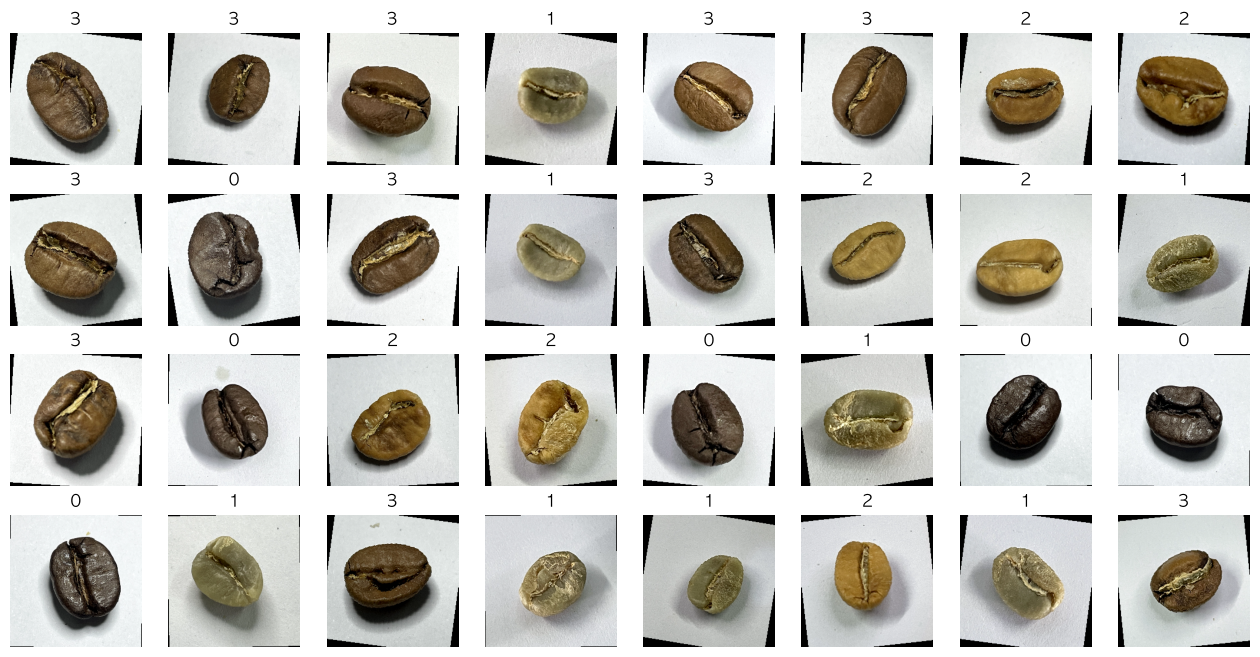

In [15]:
# 시각화
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

### 모델 Resnet

- Alexnet이 초기 CNN 구조로 이미지 분류 성능을 향상시켰지만 Resnet이 더 깊은 네트워크를 안정적으로 학습할 수 있다.
- 깊은 신경망에서는 앞쪽 층까지 학습 신호가 잘 전달되지 않는 문제가 생길 수 있는데, Resnet은 깊어져도 별도의 파라미터나 큰 계산 비용을 추가하지 않아 Gradient와 정보가 전달되기 쉬운 구조다.
- 단순히 깊기만 한 게 아니라 실제 정확도 향상을 도모했고 깊어졌는데도 계산량을 무작정 키우지 않았다.

📍 참고 : [ResNet 논문](https://arxiv.org/pdf/1512.03385) 

### ResNet18 선택 이유
- 대규모 GPU 서버가 아닌 로컬 MPS 환경에서 수행되므로 높은 분류 성능뿐만 아니라 모델 크기, 연산량, 학습 속도 및 반복 실험 가능성을 함께 고려할 필요가 있다.
- Alexnet은 대표적인 초기 CNN 모델이라 약 61M개의 파라미터를 갖는 반면, ResNet18은 약 11.7M개의 파라미터로 상대적으로 작아 모델 저장과 메모리 사용 측면에서 유리하다.
- 해당 커피 원두 데이터셋은 ImageNet과 같은 대규모 데이터가 아니라 클래스 수도 제한적이므로 ResNet50보다는 RestNet18이 과도한 계산량과 과적합 위험을 줄이면서 충분한 특징 추출 능력을 제공할 수 있다고 판단하였다.

[문제 3] 전이학습 모델 구현 & 훈련(Feature Extraction) (40점)

요구사항(공통)

선택한 베이스 모델로 특징추출 전이학습 모델을 구성하고 학습하라.

필수 조건

- 사전 모델 상위 분류기 제거 및 교체
- base model은 동결(requires_grad = False) 유지
- 분류기 헤드(필수):
- nn.AdaptiveAvgPool2d((1, 1)) (GAP 적용)
- nn.Dropout(권장)
- nn.Linear(in_features, num_classes)
- optimizer: Adam, learning_rate=0.001
- 체크포인트:
- 검증 정확도 기준 최고 성능 갱신 시 torch.save로 best 모델 저장

채점 기준(40점)

- (10점) base model 로딩 + 입력 형태 일치
- (10점) base_model 동결(requires_grad=False) 정확히 적용
- (8점) GAP 기반 헤드 구성 적절(Flatten 위주 구성은 감점)
- (6점) 손실함수/옵티마이저/학습률 설정 적절
- (6점) 최고 성능 갱신형 가중치 저장(torch.save) 로직 무결성

In [16]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [17]:
model1 = models.resnet18(weights="IMAGENET1K_V1").to(device)

In [18]:
# 모델 프리징
for param in model1.parameters():
    param.requires_grad=False

In [19]:
model1.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 4)
)

model1 = model1.to(device)

In [20]:
print(model1.fc)

Sequential(
  (0): Linear(in_features=512, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=4, bias=True)
)


### 전이 학습

In [21]:
optimizer = optim.Adam(model1.fc.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss()

In [22]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    
    sum_losses = 0.0
    sum_accs = 0.0
    
    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).long()

        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss = loss.item()
        sum_losses += batch_loss

        # 다중 분류 정확도
        y_pred_tag = torch.argmax(y_pred, dim=1)
        acc = (y_batch == y_pred_tag).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] | Batch Loss : {batch_loss:.4f}, | Batch Accuracy : {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [23]:
@torch.no_grad()
def evaluate_multi(model, dataloader, criterion, device):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).long()

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 분류 정확도
        y_pred_tag = torch.argmax(y_pred, dim=1)
        acc = (y_batch == y_pred_tag).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [24]:
def train_model_multi(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multi(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {val_loss:.8f} | Train Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================= {model_name} 학습 종료 ============================")
    return history

In [25]:
history = train_model_multi(
    model = model1,
    model_name = "Resnet18",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=20,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Resnet18 학습 시작 ============================
[Batch 20/38] | Batch Loss : 1.1496, | Batch Accuracy : 75.00%
[Epoch: 1] | Train Loss: 1.00568353 | Train Accuracy: 84.62%
[Batch 20/38] | Batch Loss : 0.8578, | Batch Accuracy : 90.62%
[Epoch: 2] | Train Loss: 0.74294883 | Train Accuracy: 86.30%
[Batch 20/38] | Batch Loss : 0.5707, | Batch Accuracy : 96.88%
[Epoch: 3] | Train Loss: 0.56208052 | Train Accuracy: 91.11%
[Batch 20/38] | Batch Loss : 0.4913, | Batch Accuracy : 93.75%
[Epoch: 4] | Train Loss: 0.44643114 | Train Accuracy: 91.83%
[Batch 20/38] | Batch Loss : 0.4265, | Batch Accuracy : 96.88%
[Epoch: 5] | Train Loss: 0.36021506 | Train Accuracy: 97.60%
[Batch 20/38] | Batch Loss : 0.3143, | Batch Accuracy : 100.00%
[Epoch: 6] | Train Loss: 0.30849525 | Train Accuracy: 96.39%
[Batch 20/38] | Batch Loss : 0.3329, | Batch Accuracy : 93.75%
[Epoch: 7] | Train Loss: 0.24899979 | Train Accuracy: 99.04%
[Batch 20/38] | Batch Loss : 0.2188, | Batch Accuracy : 96.88%

[문제 4] 모델 평가 및 측정 리포트 (30점)

요구사항

저장된 best 모델을 불러와 아래 항목을 수행하고 리포트로 작성하라.

필수 항목

1. Accuracy 측정(검증 또는 테스트)
2. 추가 지표 1개 선택(Precision/Recall/F1 중 택1 권장)
3. 혼동행렬(confusion matrix) 생성
4. 오분류 5개 이상 추출 (같은 부분에서 틀렸을 가능성이 큼. 틀린 애를 grad_cam으로 판단할 것)

- 각 샘플: 정답 라벨 / 예측 라벨 / 예측 확률(또는 점수) 포함

5. 개선 아이디어 2개 제시(파인튜닝 제외)
- 예: 증강 강화, Dropout 조정, 입력 크기/배치 조정, 데이터 불균형 대응 등
- 왜 도움이 되는지 근거 1줄 포함

채점 기준(30점)

- (8점) best 모델 로드 + 정확도 측정 재현 가능
- (6점) 추가 지표 계산 및 해석
- (8점) 혼동행렬 해석이 구체적(어떤 클래스끼리 혼동하는지)
- (8점) 오분류 5개 이상 + 확률/점수 근거 포함

### best 모델 불러오기

In [30]:
model_name = "Resnet18"
best_model_path = os.path.join(base_path, "weight", model_name, "best_model.pth")

# 가중치 없이 base_model만 가져오기
model3 = models.resnet18(weights=models.resnet18)

# 모델 프리징
for param in model1.parameters():
    param.requires_grad = False

In [27]:
# Accuracy 측정
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix)

model1.eval()

all_preds = []
all_labels = []
all_images = []

with torch.no_grad():
    for X_batch, y_batch in test_dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).long()

        outputs = model1(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
        all_images.extend(X_batch.cpu())

accuracy = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 99.25%


In [32]:
# F1 측정
f1 = f1_score(
    all_labels,
    all_preds,
    average="macro")

print(f"Macro F1-score: {f1:.4f}")

Macro F1-score: 0.9925


['Dark', 'Green', 'Light', 'Medium']


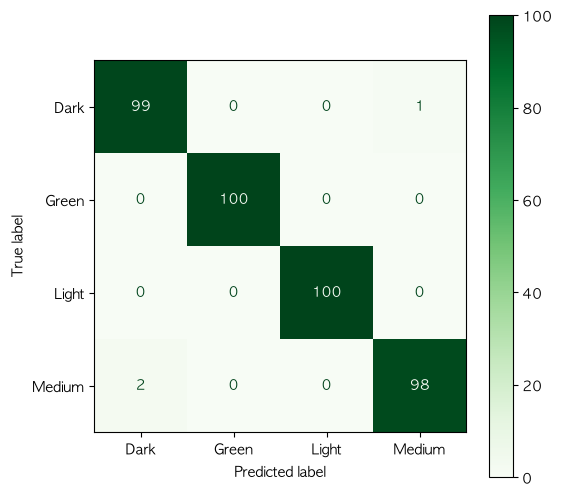

In [55]:
# Confusion Matrix 생성
from sklearn.metrics import ConfusionMatrixDisplay

class_names = train_base_dataset.classes
print(class_names)

cm = confusion_matrix(
    all_labels,
    all_preds
)

dis = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6,6))

dis.plot(
    ax=ax,
    cmap="Greens",
    values_format="d"
)

### 나의 커피 원두 로스팅 단계 평가하기

예측 단계 : Dark
예측 확률 : 38.39%


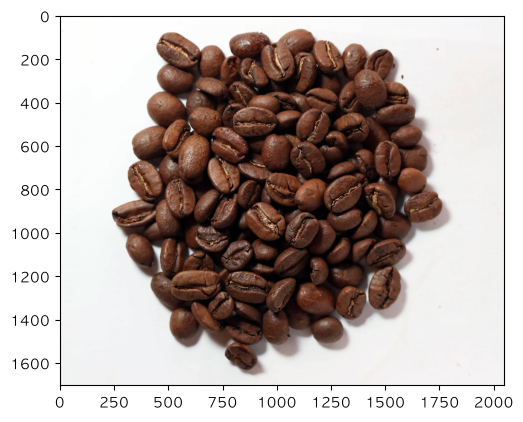

In [41]:
img_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/data_set/my_coffee_beans.jpg"
img = Image.open(img_path).convert("RGB")
img_tensor = test_transform(img).unsqueeze(0).to(device)

model1.eval()
with torch.no_grad():
    pred = model1(img_tensor)
    prob = torch.softmax(pred, dim=1)
    pred_label = torch.argmax(prob, dim=1).item()
    pred_prob = prob[0, pred_label].item()

class_names = train_base_dataset.classes

print(f"예측 단계 : {class_names[pred_label]}")
print(f"예측 확률 : {pred_prob * 100:.2f}%")

plt.imshow(img)
plt.show()

### 오분류 찾기

In [45]:
wrong_indices = [
    i
    for i, (true, pred) in enumerate(zip(all_labels, all_preds))
    if true != pred
]

print("오분류 개수:", len(wrong_indices))

오분류 개수: 3


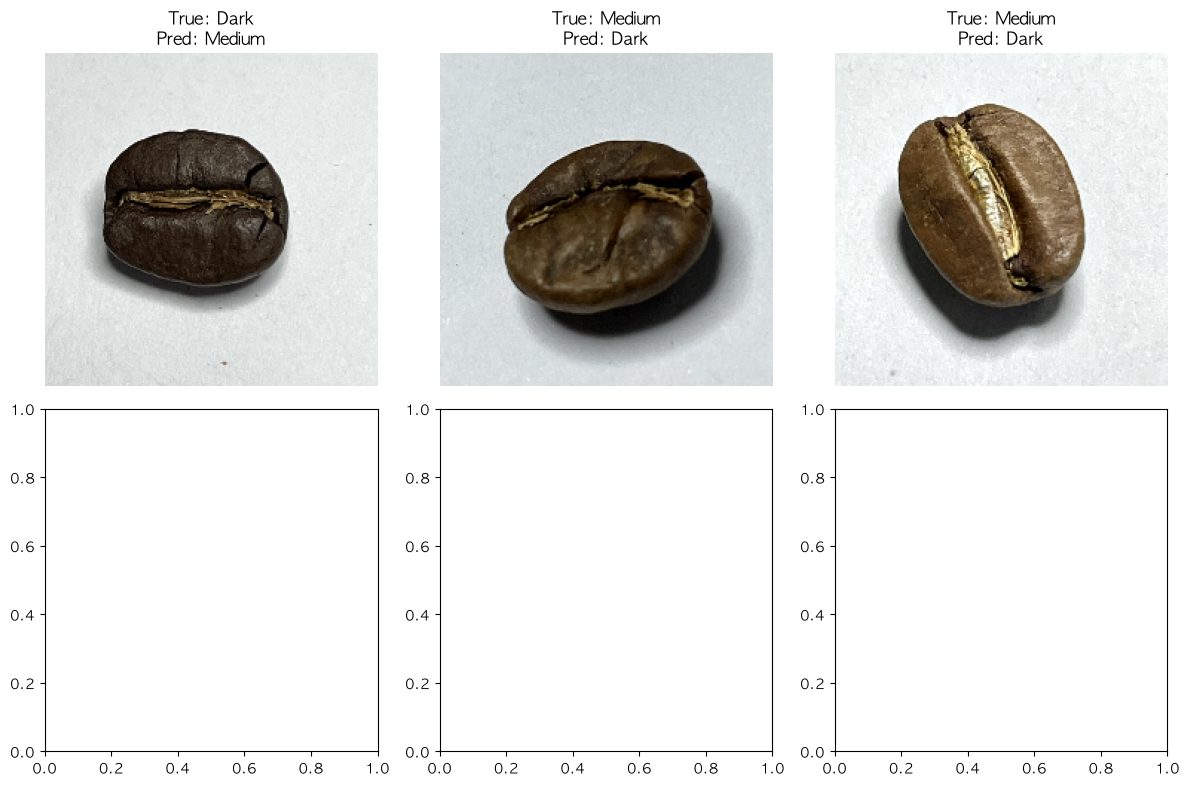

In [51]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class_names = train_base_dataset.classes
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, idx in zip(axes.flatten(), wrong_indices[:3]):
    img = all_images[idx]

    # 역정규화
    img = img * std + mean

    # (C, H, W) -> (H, W, C)
    img = img.permute(1, 2, 0)

    true_label = all_labels[idx]
    pred_label = all_preds[idx]

    ax.imshow(img.numpy())

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

[보너스] Grad-CAM 시각화로 “모델이 어디를 봤는지” 설명 (+10점)

요구사항 best 모델의 마지막 컨볼루션 층(또는 적절한 레이어)에 훅을 부착하여 Grad-CAM을 생성하고 모델의 판단 근거를 설명하라.

제출 조건 - 정분류 3장 + 오분류 2장 이상(총 5장 이상)

- 각 이미지마다 제출:
- 원본 이미지
- Grad-CAM 히트맵(overlay)
- 한 줄 해석: “모델이 어디를 보고 왜 그렇게 예측했는지”
- 오분류 2장에 대해 추가:
- 오분류 원인 추정(배경 편향/유사 패턴/노이즈 등)
- 개선 아이디어 1개(파인튜닝 제외) 채점 기준(+10점)

- (3점) 최소 5장 충족 + 시각화 품질(overlay 포함)
- (3점) 관찰이 구체적(대상 부위/특징을 정확히 언급)
- (2점) 오분류 원인 분석 타당 - (2점) 개선 아이디어가 원인과 연결

In [56]:
activations = None
gradients = None

# 모델이 이미지를 보면서 만든 featurea map 저장
def forward_hook(module, input, output):
    global activations
    activations = output

# 특정 클래스를 예측할 때 중요했던 gradient 저장
def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

In [57]:
target_layer = model1.layer4[-1]
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

In [58]:
def make_gradcam(model, img_tensor, target_class):
    global activations, gradients
    model.eval()
    # 이전 gradient가 남아있다면 초기화
    model.zero_grad()
    # 순전파
    output = model(img_tensor)
    # target class의 점수
    score = output[0, target_class]
    # 역전파
    score.backward()
    # batch 차원 제거
    acts = activations[0]
    grads = gradients[0]
    # 각 채널 gradient의 평균
    weights = grads.mean(dim=(1, 2))
    
    # Grad-CAM 생성
    cam = torch.zeros(
        acts.shape[1],
        acts.shape[2],
        device=acts.device
    )

    for i in range(len(weights)):
        cam += weights[i] * acts[i]

    # 음수 제거
    cam = torch.relu(cam)
    # 0~1 범위로 변환
    cam = cam - cam.min()
    if cam.max() != 0:
        cam = cam / cam.max()

    return cam.detach().cpu()

In [60]:
import torch.nn.functional as F

def resize_cam(cam, height=224, width=224):

    cam = cam.unsqueeze(0).unsqueeze(0)
    cam = F.interpolate(
        cam,
        size=(height, width),
        mode="bilinear",
        align_corners=False
    )

    return cam.squeeze()

In [61]:
def show_gradcam(img, cam, true_label, pred_label, class_names):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    # Normalize 되돌리기
    original_img = img.cpu() * std + mean
    # matplotlib 형태로 변경
    original_img = original_img.permute(1, 2, 0)
    # Grad-CAM 크기 맞추기
    cam = resize_cam(
        cam,
        original_img.shape[0],
        original_img.shape[1]
    )

    plt.figure(figsize=(10, 4))
    # 원본
    plt.subplot(1, 2, 1)
    plt.imshow(original_img.numpy())
    plt.title(
        f"True: {class_names[true_label]}"
    )
    plt.axis("off")

    # Grad-CAM overlay
    plt.subplot(1, 2, 2)
    plt.imshow(original_img.numpy())
    plt.imshow(
        cam.numpy(),
        cmap="jet",
        alpha=0.4
    )
    plt.title(
        f"Pred: {class_names[pred_label]}"
    )
    plt.axis("off")
    plt.show()